# Recognising daily activities from a wrist sensor

A wrist accelerometer records 24 hours of movement. Can we tell what its wearer was doing in every 10 seconds? It is hard because the recordings are of people's normal, unscripted days, and the labels come from camera photos taken every 20-40 seconds.

This notebook classifies 10 activities, the scheme of Willetts et al. (2018), on CAPTURE-24 (151 participants; Chan et al., 2024). The random forest (A) works on hand-made features of each 10 s window. The random forest + HMM (B) adds a hidden Markov model that smooths the forest's output over time.

Macro-F1 is the average score per activity, so rare activities count as much as sleep. κ (Cohen's kappa) is agreement with the labels beyond what chance would give.

- **Reproduction.** Window counts match the paper's exactly. Rerunning the paper's random forest + HMM from the authors' code gives κ 0.660 on the held-out participants, against the published 0.637, so the reproduction is faithful.
- **A strong baseline.** The random forest + HMM reaches κ 0.690 on the held-out participants. It is comparable to the rerun (paired difference +0.029 κ, interval 0.001 to 0.058) and is the baseline for part 2.
- **Two pitfalls.** Splitting sequences at annotation gaps leaks 0.02 macro-F1 that a deployed model would not have. A balanced forest with too few trees leaves some training windows with no out-of-bag prediction, which costs an HMM fitted on that output 0.075 κ (section 4).

![Held-out scores against the paper's models](outputs/results.png)

*Held-out macro-F1 and κ with 95% intervals (Figure 4).*

## Setup

Imports and configuration. A run takes about 7 min on 8 logical cores once both caches in `data/` exist. The first run also builds the feature cache (about 9 min) and the rerun of the paper's pipeline (about 18 min).

In [1]:
import json
import warnings
import zipfile
from pathlib import Path
from time import perf_counter

import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.ensemble._forest import _generate_unsampled_indices
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold

from capture24 import features as F
from capture24 import har
from capture24.har import BLUE, CLASSES, CODES, INK, ORANGE, SHOWN, draw_band, fit_hmm, metrics_from_cm, participant_cms, smooth

Settings, paths and the paper's published numbers. `har.CODES` is alphabetical, so a tied label vote resolves as pandas' `mode()` does in the paper's `prepare_data.py`.

In [2]:
T0 = perf_counter()
SEED = 42
N_FOLDS = 5
N_BOOT = 2000
N_TREES = 300
PAPER_VERSION = 1  # bump when paper_pipeline changes; it is part of the cache file name
PAPER_TREES, PAPER_BATCH = 3000, 600  # the paper's forest, fitted in batches to fit in memory
LOAD_JOBS = 4  # each worker holds about 1 GB

DATA, OUT = Path("data"), Path("outputs")
RAW = DATA / "capture24"
CACHE = DATA / f"features_w{F.WINSEC}s_v{F.FEATURE_VERSION}.parquet"
STATS_CACHE = DATA / f"participant_stats_w{F.WINSEC}s_v{F.FEATURE_VERSION}.parquet"
PAPER_CACHE = DATA / f"paper_copy_v{PAPER_VERSION}_w{F.WINSEC}s_v{F.FEATURE_VERSION}_trees{PAPER_TREES}_seed{SEED}_folds{N_FOLDS}.joblib"

SCHEME = "WillettsSpecific2018"  # the paper's 10 activities
DEV_IDS = [f"P{i:03d}" for i in range(1, 101)]  # P101-P151 is the holdout
PAPER_WINDOWS = {"all": 922_199, "P001-P100": 618_129, "P101-P151": 304_070}
PAPER = {"Paper RF": (0.388, 0.514), "Paper RF + HMM": (0.486, 0.637), "Paper CNN + HMM": (0.576, 0.735)}  # (macro-F1, kappa)

NAMES = {"A": "Random forest", "A, 30 features": "Random forest, 30 features", "B": "Random forest + HMM",
         "the paper's emission matrix (estimated)": "paper's emission matrix, covered windows"}  # display names of result keys

har.set_style()
OUT.mkdir(exist_ok=True)

## 1. Data

`capture24.zip` (CC BY 4.0, <https://doi.org/10.5287/bodleian:NGx0JOMP5>) goes in `data/`. It holds one CSV per participant (100 Hz, in g, with an annotation per sample) and two metadata files.

In [3]:
if not RAW.exists():
    zipfile.ZipFile(DATA / "capture24.zip").extractall(DATA)
FILES = sorted(RAW.glob("P[0-9][0-9][0-9].csv.gz"))
print(len(FILES), "participant files;", "other files:", sorted(p.name for p in RAW.iterdir() if p not in FILES))
pd.read_csv(FILES[0], nrows=3)

151 participant files; other files: ['annotation-label-dictionary.csv', 'metadata.csv']


,time,x,y,z,annotation
0,2016-11-13 02:18:00.000000,-0.46669,-0.533341,0.658472,7030 sleeping;MET 0.95
1,2016-11-13 02:18:00.010000,-0.46669,-0.533341,0.658472,7030 sleeping;MET 0.95
2,2016-11-13 02:18:00.020000,-0.46669,-0.533341,0.658472,7030 sleeping;MET 0.95


Each recording is cut into 10 s windows and reduced to 39 features on its own, in parallel, so the 100 Hz signal is never held in memory at once. The window table is cached in `data/`, with a few statistics per participant.

In [4]:
def load_label_codes():
    labels = pd.read_csv(RAW / "annotation-label-dictionary.csv", index_col="annotation", dtype="string")[f"label:{SCHEME}"]
    assert set(labels) == set(CLASSES), sorted(set(labels))
    return labels.map(CODES.index).astype(int)


def process_participant(path, label_codes):
    raw = F.load_participant(path)
    time, xyz = raw["time"].to_numpy(), raw[["x", "y", "z"]].to_numpy()
    annotation = raw["annotation"].cat  # codes: annotation id per sample, -1 where unlabelled
    class_of = {"10-class": label_codes[annotation.categories].to_numpy()}
    X, start, y, _ = F.make_windows(time, xyz, annotation.codes.to_numpy(), class_of)
    pid = path.name[:4]
    table = pd.concat([pd.DataFrame({"participant": pid, "window_start": start, **y}), F.extract_features(X)], axis=1)
    stats = {"participant": pid, "hours": len(raw) / F.SAMPLE_RATE / 3600,
             "nan_share": np.isnan(xyz).any(axis=1).mean(), "unlabelled_share": raw["annotation"].isna().mean(),
             "steps_over_1s": int((np.diff(time) >= np.timedelta64(1, "s")).sum())}
    return table, stats


def load_windows():
    if not (CACHE.exists() and STATS_CACHE.exists()):
        warnings.filterwarnings("ignore", message="A worker stopped")  # loky recycles workers as memory grows
        codes = load_label_codes()
        results = Parallel(n_jobs=LOAD_JOBS)(delayed(process_participant)(p, codes) for p in FILES)
        pd.concat([r[0] for r in results], ignore_index=True).to_parquet(CACHE)
        pd.DataFrame([r[1] for r in results]).to_parquet(STATS_CACHE)
    return pd.read_parquet(CACHE), pd.read_parquet(STATS_CACHE).set_index("participant")

In [5]:
windows, stats = load_windows()
LABELLED = windows["10-class"].to_numpy() >= 0
IS_DEV = windows["participant"].isin(DEV_IDS).to_numpy()
print(f"{len(stats)} participants, {stats['hours'].min():.0f} to {stats['hours'].max():.0f} h each, "
      f"{(stats['nan_share'] > 0).sum()} with missing samples, "
      f"{(stats['steps_over_1s'] > 0).sum()} with a recording gap over 1 s, "
      f"{stats['unlabelled_share'].mean():.0%} of samples unlabelled")

151 participants, 13 to 32 h each, 0 with missing samples, 8 with a recording gap over 1 s, 34% of samples unlabelled


Window rule:

- cut each recording into 10 s bins from its first sample;
- drop a bin with fewer than 1,000 samples or any missing value;
- label a bin with the most frequent class among its labelled samples, so a bin whose label changes partway is kept. A bin whose most frequent annotation is "unlabelled" stays unlabelled: the HMM decodes it, but it is never trained on, scored or counted below.

The current `prepare_data.py` labels any bin with one labelled sample, which gives 934,762 windows (+1.4%); leaving out the unlabelled-majority bins matches the paper's counts exactly.

**Table 1.** Labelled windows per split, against the paper's counts.

In [6]:
def window_counts():
    ours = {"all": int(LABELLED.sum()), "P001-P100": int((LABELLED & IS_DEV).sum()), "P101-P151": int((LABELLED & ~IS_DEV).sum())}
    table = pd.DataFrame({"ours": ours, "paper": PAPER_WINDOWS})
    table["diff %"] = (100 * (table["ours"] / table["paper"] - 1)).round(3)
    return table


COUNTS = window_counts()
COUNTS

,ours,paper,diff %
all,922199,922199,0.0
P001-P100,618129,618129,0.0
P101-P151,304070,304070,0.0


**Figure 1.** One participant's day: the mean vector magnitude per second, with the 10 activity labels underneath.

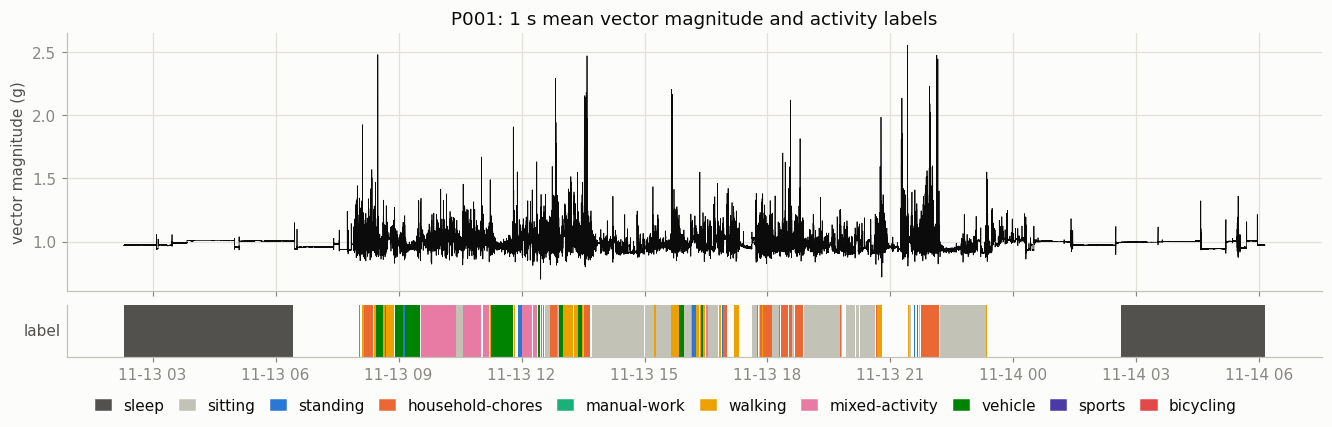

In [7]:
def plot_day(pid="P001"):
    raw = F.load_participant(RAW / f"{pid}.csv.gz")
    magnitude = pd.Series(np.linalg.norm(raw[["x", "y", "z"]].to_numpy(), axis=1), index=raw["time"]).resample("1s").mean()
    w = windows[windows["participant"] == pid]
    fig, (ax, band) = plt.subplots(2, 1, sharex=True, figsize=(12, 3.8), height_ratios=[5, 1], layout="constrained")
    ax.plot(magnitude.index, magnitude.to_numpy(), lw=0.5, color=INK)
    ax.set(ylabel="vector magnitude (g)", title=f"{pid}: 1 s mean vector magnitude and activity labels")
    draw_band(band, w["window_start"].to_numpy(), w["10-class"].to_numpy(), "label")
    har.class_legend(fig)


plot_day()

**Figure 2.** How often each activity occurs among the labelled windows of the development participants (P001-P100) and the held-out ones (P101-P151).

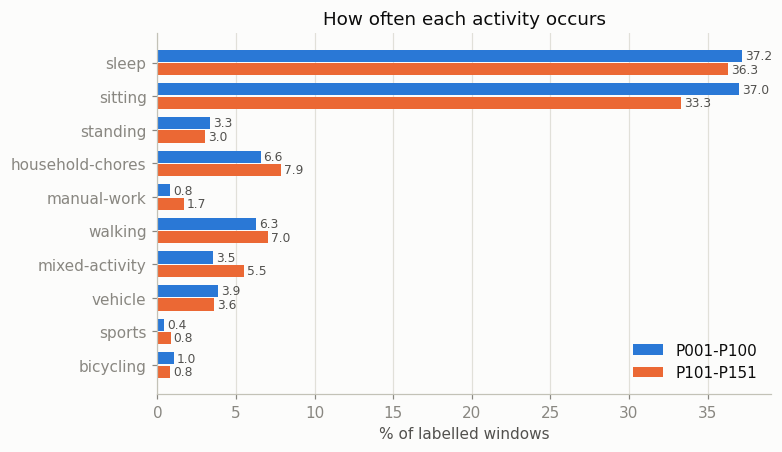

In [8]:
def plot_class_share():
    order = [CODES.index(n) for n in CLASSES]
    labels = windows["10-class"].to_numpy()

    def share(mask):
        return 100 * np.bincount(labels[mask & LABELLED], minlength=len(CLASSES))[order] / (mask & LABELLED).sum()

    _, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    y = np.arange(len(CLASSES))
    for offset, mask, label, color in ((-0.2, IS_DEV, "P001-P100", BLUE), (0.2, ~IS_DEV, "P101-P151", ORANGE)):
        bars = ax.barh(y + offset, share(mask), height=0.36, color=color, label=label)
        ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8, color="#52514e")
    ax.set(yticks=y, yticklabels=CLASSES, xlabel="% of labelled windows", title="How often each activity occurs")
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.legend()


plot_class_share()

## 2. Models

### 2.1 Random forest

Each window becomes 39 numbers computed in `capture24/features.py`. Most describe how strongly and how regularly the wrist moved: moments, quantiles, autocorrelation, spectrum and peaks of the acceleration magnitude. They follow the capture24 [feature list](https://github.com/OxWearables/capture24/blob/master/feature-list.md) without its third dominant frequency. Nine describe how the wrist was oriented: per-axis means and standard deviations, and correlations between axes. The model sees nothing else: no participant id, demographics or time of day.

The random forest is imblearn's `BalancedRandomForestClassifier` with 300 trees, where the paper's has 3,000. Each tree trains on a sample with equally many windows of every activity. It is scored two ways. The first is 5-fold cross-validation (CV) on P001-P100, with each participant in one fold only. The second is one fit on P001-P100 scored on P101-P151, the paper's holdout, which comes last, under Results.

In [9]:
X = windows[F.FEATURE_NAMES].to_numpy()
Y = windows["10-class"].to_numpy()  # -1 = unlabelled
GROUPS = windows["participant"].to_numpy()
DEV, TEST = np.flatnonzero(IS_DEV), np.flatnonzero(~IS_DEV)
ALL_FEATURES = slice(None)


def fit_forest(rows, cols=ALL_FEATURES, **kwargs):
    return har.balanced_forest(N_TREES, SEED, **kwargs).fit(X[rows][:, cols], Y[rows])


def fit_split(train, test):
    forest = fit_forest(train[Y[train] >= 0])
    return {"train": train, "test": test, "proba": forest.predict_proba(X[test])}

Five participant-grouped folds over P001-P100, stratified on the labelled windows, and one forest per fold. Each fold holds every window of its participants, labelled or not.

In [10]:
FOLDS = har.participant_folds(Y, GROUPS, np.flatnonzero(IS_DEV & LABELLED), N_FOLDS, SEED)
CV_SPLITS = [fit_split(train, valid) for train, valid in FOLDS]

### 2.2 Random forest + HMM: smoothing over time

The random forest judges each window alone, so its output flickers. People do not change activity every 10 seconds, and an HMM (Rabiner, 1989) uses that. It knows how often each activity occurs and that an activity usually continues. So it holds the current activity until the forest's output argues against it strongly and for long enough. It rarely switches, because the labels almost never show one activity directly after another (part 2 shows why).

The prior and transition matrix come from the training participants of each fit. The emission likelihood is the forest's probability vector, which is approximately proportional to $P(\text{window} \mid \text{activity})$ because each tree trains on a class-balanced sample. The random forest + HMM decodes every window of a recording, labelled or not, since a deployed model is not told where the annotation gaps are. Only labelled windows are scored. The HMM code (Viterbi decoding and fitting) is in `capture24/har.py`.

In [11]:
# A sequence breaks only where the recording does: all windows are kept, labelled or not.
SEQ = har.sequence_ids(windows["window_start"].to_numpy(), GROUPS)


def decode(split):
    train, test = split["train"], split["test"]
    hmm = fit_hmm(Y[train], SEQ[train], len(CODES))
    return smooth(split["proba"], SEQ[test], hmm)[Y[test] >= 0]


def predict(split):
    train, test = split["train"], split["test"]
    scored = Y[test] >= 0
    majority = np.bincount(Y[train][Y[train] >= 0]).argmax()
    return test[scored], {"Dummy": np.full(scored.sum(), majority), "A": split["proba"][scored].argmax(axis=1), "B": decode(split)}

Each fold's labelled validation windows, with three predictions for them: the most common training activity (a dummy, for scale), the random forest and the random forest + HMM.

In [12]:
CV_PRED = [predict(split) for split in CV_SPLITS]

### 2.3 The paper's pipeline as a baseline

For a like-for-like bar, the paper's random forest + HMM is rerun here on the same folds and the same holdout. Its configuration was fixed from the paper's code (`rf.py`, `classifier.py`, `hmm.py`) before any score was seen, and it was run once:

- the forest is imblearn's balanced random forest with 3,000 trees, on the 30 features that do not describe orientation;
- the HMM sees only the forest's top class, through an emission matrix averaged from the forest's out-of-bag output; it has a uniform prior and decodes labelled windows only, as one sequence per participant. That protocol knows at test time which windows have labels, a mild form of the annotation-gap leak measured in section 4, though on these folds it does not help.

Three things differ from the paper's own run. The features are this notebook's code and cover 30 of the paper's 32, without the third dominant frequency and its power. The 3,000 trees are fitted in batches of 600 with different seeds. This keeps memory under 16 GB. And the paper's code can load tuned forest settings that its repo does not include, so the defaults are used.

`decode_with` is the HMM decoding with the paper's three HMM choices exposed, so the ablation below can swap them one at a time.

In [13]:
PAPER_FEATURES = [i for i, name in enumerate(F.FEATURE_NAMES) if not name.startswith(("x_", "y_", "z_", "corr_"))]
PARTICIPANT_SEQ = pd.factorize(GROUPS)[0]


def matrix_lik(output, truth, proba):
    """The paper's emission model: the HMM sees only the forest's top class. emit[true class] is the mean of `output`
    (forest output for training windows) over that class, as in hmm.py."""
    emit = np.stack([output[truth == c].mean(axis=0) for c in range(output.shape[1])])
    return emit[:, proba.argmax(axis=1)].T


def decode_with(split, lik, seq=SEQ, labelled_only=False, uniform_prior=False):
    train, test = split["train"], split["test"]
    scored = Y[test] >= 0
    if labelled_only:
        train, test, lik, scored = train[Y[train] >= 0], test[scored], lik[scored], scored[scored]
    hmm = fit_hmm(Y[train], seq[train], lik.shape[1])
    if uniform_prior:
        hmm["prior"] = np.full(lik.shape[1], 1 / lik.shape[1])
    return smooth(lik, seq[test], hmm)[scored]

The paper fits its emission matrix on the forest's out-of-bag output. `oob_sums` recomputes that output tree by tree, so the windows that get none can be counted, and `expected_uncovered` predicts their share from the class sizes alone.

In [14]:
def oob_sums(forest, features):
    """Sum of out-of-bag tree probabilities, and number of out-of-bag trees, per training window. imblearn's rule:
    a window is out-of-bag for a tree if it is in that tree's undersampled pool and the tree's bootstrap missed it."""
    total, count = np.zeros((len(features), forest.n_classes_)), np.zeros(len(features))
    for sampler, tree in zip(forest.samplers_, forest.estimators_):
        pool = sampler.sample_indices_
        out = pool[_generate_unsampled_indices(tree.random_state, len(pool), len(pool))]
        total[out] += tree.predict_proba(features[out])
        count[out] += 1
    return total, count


def uncovered_share(count, truth):
    return np.bincount(truth, weights=count == 0) / np.bincount(truth)


def expected_uncovered(truth, trees):
    """Share of each class's windows expected to get no out-of-bag output. A window is in a tree's pool with
    probability about 1 - exp(-smallest class / its class), and the bootstrap then misses it with probability 1/e."""
    n = np.bincount(truth)
    return (1 - (1 - np.exp(-n.min() / n)) / np.e) ** trees

The whole pipeline, run on each CV fold and then on the holdout. Each run takes minutes, so each is cached as it finishes.

In [15]:
def paper_pipeline(train, test):
    """The paper's RF + HMM as classifier.py and hmm.py have it -> predictions for the labelled windows of `test`,
    and the share of training windows per class without out-of-bag output."""
    labelled, scored = train[Y[train] >= 0], test[Y[test] >= 0]
    features, total, count, proba = X[labelled][:, PAPER_FEATURES], 0, 0, 0
    for batch in range(PAPER_TREES // PAPER_BATCH):
        forest = fit_forest(labelled, PAPER_FEATURES, n_estimators=PAPER_BATCH, random_state=SEED + batch)
        sums = oob_sums(forest, features)
        total, count = total + sums[0], count + sums[1]
        proba = proba + forest.predict_proba(X[scored][:, PAPER_FEATURES])
    oob = total / np.maximum(count, 1)[:, None]  # like imblearn, a window without out-of-bag output keeps a row of zeros
    pred = decode_with({"train": train, "test": scored}, matrix_lik(oob, Y[labelled], proba),
                       PARTICIPANT_SEQ, labelled_only=True, uniform_prior=True)
    return pred, uncovered_share(count, Y[labelled])


def paper_copy():
    splits = [(split["train"], split["test"]) for split in CV_SPLITS] + [(DEV, TEST)]
    done = joblib.load(PAPER_CACHE) if PAPER_CACHE.exists() else []
    for train, test in splits[len(done):]:
        done.append(paper_pipeline(train, test))
        joblib.dump(done, PAPER_CACHE)
    return done[:-1], done[-1]

## 3. Results

Scores come from confusion matrices: one per fold in CV, and one per held-out participant, so that participants can be resampled. Holdout intervals are 95% percentile bootstraps over participants, with 2,000 draws (Field & Welsh, 2007), because windows from one person are correlated. The paper says only "bootstrapping (n=100)"; its repo's `eval.py` resamples participants.

The holdout models are fitted here, after everything above was settled.

In [16]:
HOLDOUT = fit_split(DEV, TEST)
SCORED = TEST[LABELLED[TEST]]
PRED = predict(HOLDOUT)[1]
PAPER_CV, PAPER_HOLDOUT = paper_copy()

*Figure 3.* Six hours of one held-out participant: the camera labels, the random forest and the random forest + HMM. Only labelled windows are drawn, so blank stretches have no camera label.

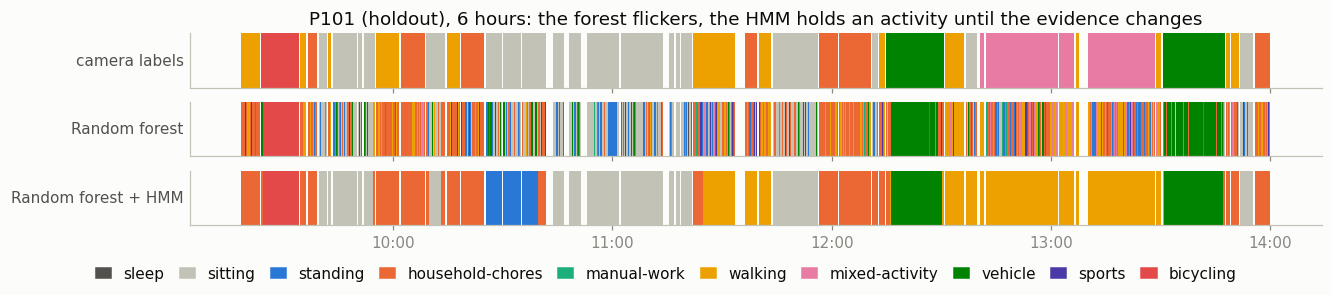

In [17]:
def plot_bands(pid="P101", first_hour=8, hours=6):
    start = windows["window_start"].to_numpy()[SCORED]
    begin = start[GROUPS[SCORED] == pid].min().astype("datetime64[D]") + np.timedelta64(first_hour, "h")
    shown = (GROUPS[SCORED] == pid) & (start >= begin) & (start < begin + np.timedelta64(hours, "h"))
    bands = {"camera labels": Y[SCORED], NAMES["A"]: PRED["A"], NAMES["B"]: PRED["B"]}
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(12, 2.6), layout="constrained")
    for ax, (name, codes) in zip(axes, bands.items()):
        draw_band(ax, start[shown], codes[shown], name)
    axes[0].set_title(f"{pid} (holdout), {hours} hours: the forest flickers, the HMM holds an activity until the evidence changes")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    har.class_legend(fig)
    fig.savefig(OUT / "bands.png", dpi=150)


plot_bands()

The excerpt is the first holdout participant, 08:00 to 14:00 on their first day, picked by position alone. Their labels start at about 09:20. The HMM removes the forest's flicker and gets the long sitting and vehicle spells right. It also turns both long mixed-activity spells into walking. Figure 5 shows this error in general: 43% of held-out mixed-activity windows become walking.

In [18]:
def confusion(rows, pred):
    return confusion_matrix(Y[rows], pred, labels=range(len(CODES)))


def holdout_cms(pred):
    return participant_cms(Y[SCORED], pred, GROUPS[SCORED], len(CODES))


def score_holdout(pred):
    cms = holdout_cms(pred)
    point, boots = metrics_from_cm(cms.sum(axis=0)), har.bootstrap_metrics(cms, N_BOOT, SEED)
    return {**{m: har.interval(point[m], boots[m]) for m in SHOWN},
            "per_class_f1": dict(zip(CODES, point["per_class_f1"])), "cm": cms.sum(axis=0)}

In [19]:
CV_CM = {model: [confusion(rows, preds[model]) for rows, preds in CV_PRED] for model in ("Dummy", "A", "B")}
CV = pd.DataFrame([{"model": model, "fold": fold, **metrics_from_cm(cm)} for model, cms in CV_CM.items() for fold, cm in enumerate(cms)]
                  ).groupby("model")[list(SHOWN)].agg(["mean", "std"])
SCORES = {model: score_holdout(pred) for model, pred in PRED.items()}
COPY_CV = pd.DataFrame([metrics_from_cm(confusion(rows, pred)) for (rows, _), (pred, _) in zip(CV_PRED, PAPER_CV)])[list(SHOWN)]
COPY = score_holdout(PAPER_HOLDOUT[0])
GAIN = har.paired_gain(holdout_cms(PRED["B"]), holdout_cms(PAPER_HOLDOUT[0]), SHOWN, N_BOOT, SEED)
print("holdout, random forest + HMM minus the rerun of the paper's pipeline, paired by participant:",
      "; ".join(f"{name} {GAIN[m]['value']:+.3f} [{GAIN[m]['ci'][0]:+.3f}, {GAIN[m]['ci'][1]:+.3f}]" for m, name in SHOWN.items()))

holdout, random forest + HMM minus the rerun of the paper's pipeline, paired by participant: macro-F1 +0.031 [-0.011, +0.080]; κ +0.029 [+0.001, +0.058]


*Table 2.* Cross-validation (mean ± standard deviation over the five folds) and holdout [95% interval], next to the paper's published holdout numbers.

In [20]:
def results_table():
    scored = {NAMES["A"]: (CV.loc["A"], SCORES["A"]),
              NAMES["B"]: (CV.loc["B"], SCORES["B"]),
              "Paper's RF + HMM (rerun)": (COPY_CV.agg(["mean", "std"]).unstack(), COPY)}
    rows = {}
    for label, (cv, holdout) in scored.items():
        rows[label] = {}
        for m, name in SHOWN.items():
            h = holdout[m]
            rows[label][f"{name} CV"] = f"{cv[m, 'mean']:.3f} ± {cv[m, 'std']:.3f}"
            rows[label][f"{name} holdout"] = f"{h['value']:.3f} [{h['ci'][0]:.3f}, {h['ci'][1]:.3f}]"
    for model, numbers in PAPER.items():
        rows[f"{model}, published"] = {f"{name} holdout": f"{n:.3f}" for name, n in zip(SHOWN.values(), numbers)}
    return pd.DataFrame(rows).T.fillna("")


results_table()

,macro-F1 CV,macro-F1 holdout,κ CV,κ holdout
Random forest,0.406 ± 0.017,"0.415 [0.380, 0.438]",0.535 ± 0.014,"0.530 [0.503, 0.555]"
Random forest + HMM,0.522 ± 0.033,"0.566 [0.524, 0.595]",0.708 ± 0.025,"0.690 [0.653, 0.725]"
Paper's RF + HMM (rerun),0.517 ± 0.041,"0.535 [0.490, 0.566]",0.670 ± 0.030,"0.660 [0.630, 0.692]"
"Paper RF, published",,0.388,,0.514
"Paper RF + HMM, published",,0.486,,0.637
"Paper CNN + HMM, published",,0.576,,0.735


*Figure 4.* Held-out macro-F1 and κ with 95% intervals. Diamonds are the cross-validation means, and grey bars are the paper's published numbers.

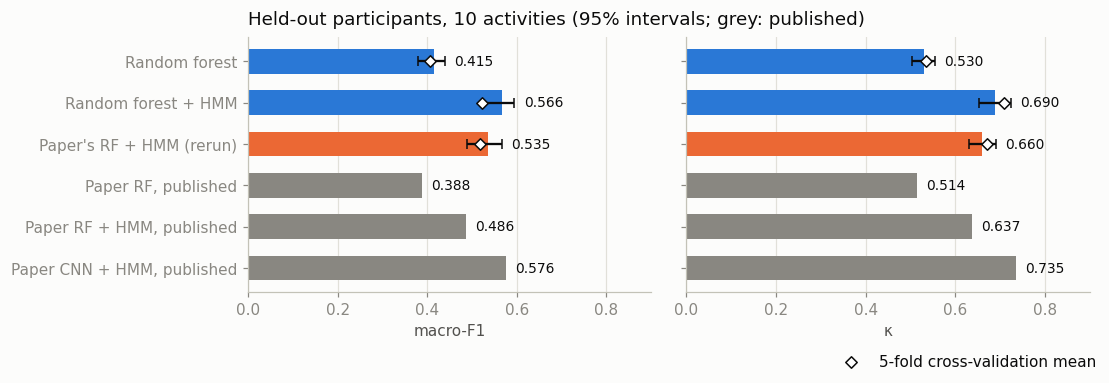

In [21]:
def plot_results():
    models = {NAMES["A"]: (SCORES["A"], CV.loc["A"].xs("mean", level=1), BLUE),
              NAMES["B"]: (SCORES["B"], CV.loc["B"].xs("mean", level=1), BLUE),
              "Paper's RF + HMM (rerun)": (COPY, COPY_CV.mean(), ORANGE)}
    published = {f"{name}, published": numbers for name, numbers in PAPER.items()}
    title = "Held-out participants, 10 activities (95% intervals; grey: published)"
    fig = har.plot_holdout(models, published, title)
    fig.savefig(OUT / "results.png", dpi=150)


plot_results()

The rerun of the paper's pipeline scores a little above the published numbers. The published κ, 0.637, is inside the rerun's interval, so the reproduction is faithful. The paper's CNN + HMM is above the random forest + HMM on κ, and its macro-F1 is inside the random forest + HMM's interval.

Both models predicted the same windows, so their difference can be paired: on each bootstrap draw of participants, one score minus the other. The random forest + HMM minus the rerun is +0.029 κ (0.001 to 0.058). For macro-F1 it is +0.031 (-0.011 to 0.080). The two are comparable, and the random forest + HMM is the baseline for part 2.

The random forest + HMM's holdout macro-F1 is 0.044 above its CV macro-F1, while its κ is lower. One activity explains that: sports, in the per-class table below.

*Figure 5.* The random forest + HMM's holdout confusion matrix, normalised by row: where each true activity ends up.

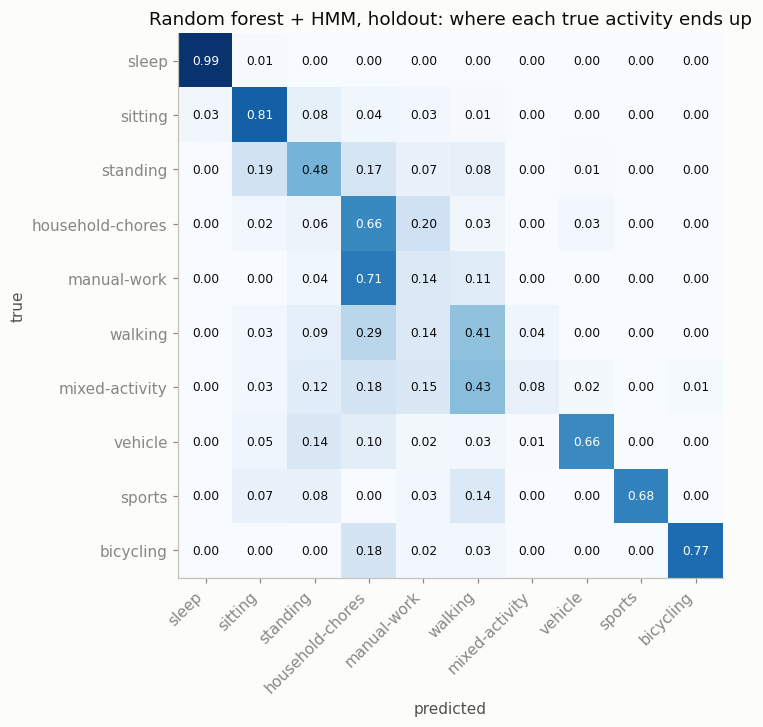

In [22]:
def plot_confusion():
    order = [CODES.index(n) for n in CLASSES]
    cm = SCORES["B"]["cm"][np.ix_(order, order)]
    cm = cm / cm.sum(axis=1, keepdims=True)
    _, ax = plt.subplots(figsize=(7.5, 6.5), layout="constrained")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(order)):
        for j in range(len(order)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.5 else INK)
    ax.set(xticks=range(len(order)), yticks=range(len(order)), yticklabels=CLASSES, xlabel="predicted", ylabel="true",
           title=f"{NAMES['B']}, holdout: where each true activity ends up")
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.grid(False)


plot_confusion()

*Table 3.* F1 per activity for the random forest and the random forest + HMM, in cross-validation (folds pooled) and on the holdout. Pooled F1 comes from one confusion matrix over all five folds, so its mean differs from Table 2's per-fold macro-F1.

In [23]:
def per_class_f1():
    table = pd.DataFrame({f"{NAMES[m]} CV": metrics_from_cm(sum(CV_CM[m]))["per_class_f1"] for m in ("A", "B")}, index=CODES)
    for m in ("A", "B"):
        table[f"{NAMES[m]} holdout"] = pd.Series(SCORES[m]["per_class_f1"])
    return table.loc[CLASSES].round(3)


sports = Y[SCORED] == CODES.index("sports")
print(f"holdout participants with sports windows: {len(set(GROUPS[SCORED][sports]))} of {len(set(GROUPS[SCORED]))}; "
      f"sports is {sports.mean():.2%} of holdout windows")
per_class_f1()

holdout participants with sports windows: 8 of 51; sports is 0.85% of holdout windows


,Random forest CV,Random forest + HMM CV,Random forest holdout,Random forest + HMM holdout
sleep,0.892,0.970,0.908,0.980
sitting,0.681,0.861,0.687,0.873
standing,0.179,0.277,0.176,0.300
household-chores,0.447,0.596,0.416,0.531
manual-work,0.113,0.146,0.059,0.072
walking,0.313,0.422,0.331,0.426
mixed-activity,0.251,0.184,0.259,0.136
vehicle,0.454,0.792,0.423,0.733
sports,0.136,0.251,0.317,0.802
bicycling,0.692,0.820,0.570,0.810


Sports F1 is 0.80 on the holdout and 0.25 in CV. Only 8 holdout participants did any sport, so the holdout macro-F1 rests on a handful of people.

Figure 5 shows where the rare activities go. The random forest + HMM reads 71% of held-out manual-work windows as household chores. It reads 43% of mixed-activity windows as walking, and the labels themselves overlap. Smoothing helps most activities but lowers mixed-activity (Table 3).

## 4. The paper's choices one at a time, and two pitfalls

The cells below rerun the five CV folds with one of the random forest + HMM's choices swapped at a time, next to the rerun of the paper's whole pipeline. Each change is measured fold by fold against the random forest + HMM. The emission rows swap the forest's probability vector for the paper's top-class emission matrix (section 2.3). "The paper's sequences" also uses its uniform prior, which only touches the first window of each sequence.

Two extra inputs for the variants: sequences that also break at every annotation gap (the leak), and an emission matrix fitted on out-of-fold forest output, which is how to avoid the out-of-bag pitfall.

In [24]:
# Labelled windows only, with a new sequence wherever one is missing.
LABELLED_SEQ = har.sequence_ids(windows["window_start"].to_numpy(), GROUPS, LABELLED)
OOF_FOLDS, OOF_TREES = 3, 50


def out_of_fold_proba(rows):
    proba = np.empty((len(rows), len(CODES)))
    folds = StratifiedGroupKFold(OOF_FOLDS, shuffle=True, random_state=SEED).split(rows, Y[rows], GROUPS[rows])
    for fit, held in folds:
        proba[held] = fit_forest(rows[fit], n_estimators=OOF_TREES).predict_proba(X[rows[held]])
    return proba

One fold's predictions for every variant, plus the share of its training windows that the 300-tree forest leaves without out-of-bag output, measured and predicted.

In [25]:
def ablation_fold(split, paper_pred):
    train, test = split["train"], split["test"]
    labelled, scored = train[Y[train] >= 0], Y[test] >= 0
    truth = Y[labelled]
    with warnings.catch_warnings():  # the warning is counted instead, below
        warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")
        forest = fit_forest(labelled, oob_score=True)  # this fold's forest again, for its out-of-bag output
    oob, (total, count) = forest.oob_decision_function_, oob_sums(forest, X[labelled])
    assert np.allclose(oob, total / np.maximum(count, 1)[:, None]), "oob_sums does not reproduce imblearn's out-of-bag output"
    uncovered = count == 0
    split30 = {**split, "proba": fit_forest(labelled, PAPER_FEATURES).predict_proba(X[test][:, PAPER_FEATURES])}

    def matrix(output, truth):
        return decode_with(split, matrix_lik(output, truth, split["proba"]))

    return {
        "A": split["proba"][scored].argmax(axis=1),
        "A, 30 features": split30["proba"][scored].argmax(axis=1),
        "B": decode(split),
        "sequences split at annotation gaps": decode_with(split, split["proba"], LABELLED_SEQ, labelled_only=True),
        "emission matrix, fitted out-of-fold": matrix(out_of_fold_proba(labelled), truth),
        # Out-of-bag output of covered windows: what 3,000 trees give, estimated from the forest's 300.
        "the paper's emission matrix (estimated)": matrix(oob[~uncovered], truth[~uncovered]),
        "emission matrix from 300-tree out-of-bag output": matrix(oob, truth),
        "30 features": decode(split30),
        "the paper's sequences": decode_with(split, split["proba"], PARTICIPANT_SEQ, labelled_only=True, uniform_prior=True),
        "the paper's whole pipeline": paper_pred,
    }, uncovered_share(count, truth), expected_uncovered(truth, N_TREES)


def ablation():
    folds = [ablation_fold(split, pred) for split, (pred, _) in zip(CV_SPLITS, PAPER_CV)]
    scores = pd.DataFrame([{"variant": name, "fold": fold, **metrics_from_cm(confusion(rows, pred))}
                           for fold, ((rows, _), (preds, _, _)) in enumerate(zip(CV_PRED, folds))
                           for name, pred in preds.items()]).set_index(["variant", "fold"])
    uncovered = pd.DataFrame({f"{N_TREES} trees": np.mean([u for _, u, _ in folds], axis=0),
                              f"{N_TREES} trees, by the rule": np.mean([e for _, _, e in folds], axis=0),
                              f"{PAPER_TREES:,} trees": np.mean([u for _, u in PAPER_CV], axis=0)}, index=CODES)
    return scores, uncovered.loc[CLASSES]

The share of sleep and sitting training windows that get no out-of-bag output: with the random forest's 300 trees, measured and by the rule in `expected_uncovered`, and with the paper's 3,000 trees.

In [26]:
ABLATION, UNCOVERED = ablation()
SLEEP_SITTING = UNCOVERED.loc[["sleep", "sitting"]].mean()
print(f"sleep and sitting training windows without out-of-bag output: {N_TREES} trees {SLEEP_SITTING.iloc[0]:.0%} "
      f"(by the rule {SLEEP_SITTING.iloc[1]:.0%}); {PAPER_TREES:,} trees {SLEEP_SITTING.iloc[2]:.0%}")

sleep and sitting training windows without out-of-bag output: 300 trees 29% (by the rule 29%); 3,000 trees 0%


*Table 4.* Each variant on the five CV folds: mean scores, and the change against the random forest + HMM as mean ± standard error of the per-fold differences.

In [27]:
def ablation_table():
    scores = ABLATION[list(SHOWN)]
    change = scores.sub(scores.loc["B"], level="fold").groupby("variant", sort=False)
    table = scores.groupby("variant", sort=False).mean().round(3).rename(columns=SHOWN)
    for m, name in SHOWN.items():
        table[f"{name} against {NAMES['B']}"] = [f"{mean:+.3f} ± {sem:.3f}" for mean, sem in zip(change[m].mean(), change[m].sem())]
    return table.rename(index=NAMES)


ablation_table()

,macro-F1,κ,macro-F1 against Random forest + HMM,κ against Random forest + HMM
variant,,,,
Random forest,0.406,0.535,-0.115 ± 0.012,-0.173 ± 0.009
"Random forest, 30 features",0.375,0.488,-0.147 ± 0.015,-0.221 ± 0.008
Random forest + HMM,0.522,0.708,+0.000 ± 0.000,+0.000 ± 0.000
sequences split at annotation gaps,0.543,0.724,+0.021 ± 0.005,+0.015 ± 0.004
"emission matrix, fitted out-of-fold",0.495,0.706,-0.027 ± 0.015,-0.002 ± 0.010
"paper's emission matrix, covered windows",0.521,0.707,-0.001 ± 0.015,-0.002 ± 0.010
emission matrix from 300-tree out-of-bag output,0.504,0.633,-0.018 ± 0.018,-0.075 ± 0.024
30 features,0.559,0.703,+0.037 ± 0.016,-0.005 ± 0.005
the paper's sequences,0.529,0.697,+0.007 ± 0.007,-0.012 ± 0.005


*Figure 6.* The changes from Table 4 that separate the random forest + HMM from the paper's pipeline, and the two pitfalls.

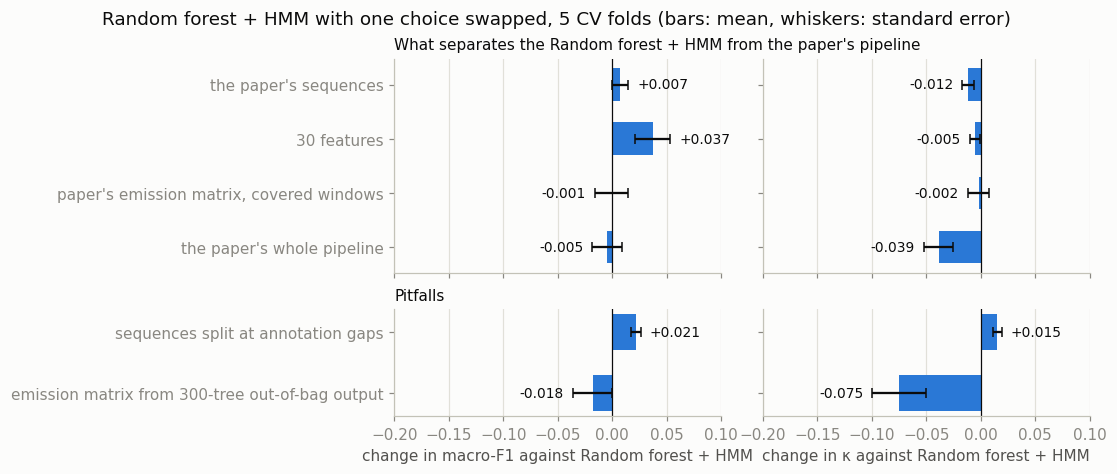

In [28]:
CHART_ROWS = {f"What separates the {NAMES['B']} from the paper's pipeline": ["the paper's sequences", "30 features",
                                                             "the paper's emission matrix (estimated)",
                                                             "the paper's whole pipeline"],
              "Pitfalls": ["sequences split at annotation gaps", "emission matrix from 300-tree out-of-bag output"]}


def plot_ablation():
    fig, axes = plt.subplots(2, 2, figsize=(10, 4.2), sharex=True, sharey="row", layout="constrained",
                             height_ratios=[len(rows) for rows in CHART_ROWS.values()])
    for row, (title, variants) in zip(axes, CHART_ROWS.items()):
        for ax, metric in zip(row, SHOWN):
            change = pd.DataFrame({v: ABLATION.loc[v, metric] - ABLATION.loc["B", metric] for v in variants})
            ax.barh([NAMES.get(v, v) for v in variants], change.mean(), xerr=change.sem(), color=BLUE, height=0.6, ecolor=INK, capsize=3)
            har.label_bars(ax, change.mean(), change.sem(), "+.3f")
            ax.axvline(0, color=INK, lw=0.8)
            ax.set(xlim=(-0.2, 0.1))
            ax.grid(axis="y", visible=False)
        row[0].invert_yaxis()
        row[0].set_title(title, loc="left", fontsize=10)
    for ax, name in zip(axes[-1], SHOWN.values()):
        ax.set_xlabel(f"change in {name} against {NAMES['B']}")
    fig.suptitle(f"{NAMES['B']} with one choice swapped, 5 CV folds (bars: mean, whiskers: standard error)")


plot_ablation()

- Each of the paper's choices moves κ by little against the random forest + HMM. Its emission matrix costs 0.002 κ and its 30 features 0.005. Its sequences cost 0.012. The whole pipeline is 0.039 κ below, with a standard error of 0.013. Tree count was never swapped.
- Pitfall 1: sequences split at annotation gaps leak. The gaps tell the HMM where an activity starts and ends. That is worth 0.021 macro-F1 that a deployed model would not get. The random forest + HMM decodes every window.
- Pitfall 2: too few trees for the out-of-bag fit. The paper fits its emission matrix on out-of-bag output, where each training window is scored only by trees that did not train on it. In a balanced forest a sleep or sitting window is out-of-bag for about one tree in 300. With 300 trees, 29% of sleep and sitting training windows get no out-of-bag output, matching the rule in `expected_uncovered`; with 3,000 trees, none. Those windows keep a row of zeros, which shrinks two rows of the emission matrix and costs 0.075 κ. Leaving them out or fitting the matrix out-of-fold fixes it. imblearn only warns "Some inputs do not have OOB scores", which is easy to filter out.

## 5. Saved results

Every score goes to `outputs/results.json`, which part 2 reads.

In [29]:
def save_results():
    change = ABLATION[list(SHOWN)].sub(ABLATION.loc["B", list(SHOWN)], level="fold")
    results = {"config": {"seed": SEED, "n_folds": N_FOLDS, "n_boot": N_BOOT, "n_trees": N_TREES, "winsec": F.WINSEC,
                          "n_features": len(F.FEATURE_NAMES), "scheme": SCHEME},
               "windows": COUNTS.to_dict(), "paper": {"10-class": PAPER},
               "paper_copy_10-class": {"n_trees": PAPER_TREES, "n_features": len(PAPER_FEATURES),
                                       "cv": COPY_CV.agg(["mean", "std"]).to_dict(),
                                       "holdout": {m: COPY[m] for m in SHOWN}, "holdout_per_class_f1": COPY["per_class_f1"],
                                       "holdout_B_minus_copy": GAIN},
               "ablation_10-class_cv": {
                   "mean": ABLATION[list(SHOWN)].groupby("variant", sort=False).mean().to_dict("index"),
                   "change_against_B_mean": change.groupby("variant", sort=False).mean().to_dict("index"),
                   "change_against_B_std": change.groupby("variant", sort=False).std().to_dict("index")},
               "tasks": {"10-class": {model: {"cv": {m: dict(zip(("mean", "std"), CV.loc[model, m])) for m in SHOWN},
                                              "holdout": {m: SCORES[model][m] for m in SHOWN},
                                              "holdout_per_class_f1": SCORES[model]["per_class_f1"]}
                                      for model in ("Dummy", "A", "B")}}}
    (OUT / "results.json").write_text(json.dumps(results, indent=2))


save_results()
print(f"run time: {(perf_counter() - T0) / 60:.1f} min")

run time: 6.7 min


## 6. Limitations

- Labels come from camera frames 20-40 s apart, and all participants were recruited around Oxford.
- Rare activities come from few people. Only 8 held-out participants did any sport, so the CV macro-F1 of 0.522 is the safer figure.
- Design choices were made on the same CV folds that are reported, and the random forest + HMM has been scored on the holdout twice over the project.

Part 2, [`02_pretrained_encoder_and_context.ipynb`](02_pretrained_encoder_and_context.ipynb), looks at where the errors are, replaces the forest with a pretrained encoder, and covers the remaining limitations.

## References

- Chan, S., Yuan, H., Tong, C., Acquah, A., Schonfeldt, A., Gershuny, J., & Doherty, A. (2024). CAPTURE-24: A large dataset of wrist-worn activity tracker data collected in the wild for human activity recognition. *Scientific Data*, 11, 1135. https://doi.org/10.1038/s41597-024-03960-3
- Chan Chang, S., Walmsley, R., Gershuny, J., Harms, T., Thomas, E., Milton, K., Kelly, P., Foster, C., Wong, A., Gray, N., Haque, S., Hollowell, S., & Doherty, A. (2021). *Capture-24: Activity tracker dataset for human activity recognition* [Data set]. University of Oxford. https://doi.org/10.5287/bodleian:NGx0JOMP5
- Field, C. A., & Welsh, A. H. (2007). Bootstrapping clustered data. *Journal of the Royal Statistical Society: Series B*, 69(3), 369-390. https://doi.org/10.1111/j.1467-9868.2007.00593.x
- OxWearables. *capture24*: benchmark code and feature list for CAPTURE-24. https://github.com/OxWearables/capture24
- Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE*, 77(2), 257-286. https://doi.org/10.1109/5.18626
- Willetts, M., Hollowell, S., Aslett, L., Holmes, C., & Doherty, A. (2018). Statistical machine learning of sleep and physical activity phenotypes from sensor data in 96,220 UK Biobank participants. *Scientific Reports*, 8, 7961. https://doi.org/10.1038/s41598-018-26174-1